# Day 17 — Improved Pricing Decision Engine

**Date:** 31 October 2026  
**Internship Role:** Data Analyst Intern at Infotact Solutions  
**Project:** EconoCausal — Causal Demand Estimation and Dynamic Pricing  

---

## Executive Overview

On **Days 11 and 12**, a prototype pricing simulator and recommendation notebook were constructed for a single product. On **Day 17**, we upgrade this into an **Improved Pricing Decision Engine** designed for institutional decision-making.

### Key Enhancements:
1. **Empirical Causal Treatment Effects:** Embeds the verified Double Machine Learning (DML) treatment effects and 95% confidence intervals from Days 10 and 15.
2. **Standardized Scenario Analysis:** Evaluates candidate relative price variations ($-10\%$, $-5\%$, $0\%$, $+5\%$, $+10\%$).
3. **Multi-Product and Category Scope:** Extends evaluation beyond a single isolated item to representative products across all 5 retail categories (Clothing, Electronics, Furniture, Groceries, Toys).
4. **Physical Business Constraints:** Enforces price positivity ($P > 0$), demand non-negativity ($\hat{D} \ge 0$), and on-hand inventory bounds ($S = \min(\hat{D}, I)$).
5. **Economic Rigor on Profit vs. Revenue:** Demonstrates why revenue maximization diverges from profit maximization, audits the dataset for unit cost data, and explicitly notes the limitation that profit optimization cannot be performed without procurement cost accounting data.
6. **Actionable Risk Rating:** Categorizes pricing scenarios into operational risk bands (Status Quo vs. Micro-test vs. Rejection).


In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/hasikaippili/Documents/EconoCausal


## 1 · Ingestion of Validated Causal Parameters

We load the verified Double Machine Learning (DML) results established in Robinson's partially linear model:
$$\tilde{Y}_{it} = \theta \tilde{P}_{it} + \varepsilon_{it}$$

where:
- Treatment ($P$): Product unit selling price in dollars ($\$$).
- Outcome ($Y$): Units sold per day.
- Nuisance Model: Cross-fitted tree ensemble partialling out multi-level fixed effects and temporal patterns.


In [2]:
DML_RESULTS_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dml_validated_results.json'
with open(DML_RESULTS_PATH) as f:
    dml_data = json.load(f)

spec1 = dml_data['spec1']
THETA = spec1['theta']
CI_LOW = spec1['ci_low']
CI_HIGH = spec1['ci_high']
SE = spec1['std_err']
P_VALUE = spec1['p_value']

print("VALIDATED DML ESTIMATES (Specification 1 - Core Controls):")
print(f"  Point Estimate (theta) : {THETA:+.6f} units / $1.00 price increase")
print(f"  Standard Error (HC3)   : {SE:.6f}")
print(f"  95% Confidence Interval: [{CI_LOW:+.6f}, {CI_HIGH:+.6f}]")
print(f"  p-value                : {P_VALUE:.4f} (Statistically insignificant at alpha = 0.05)")
print(f"  Validation Status      : {dml_data.get('validated', False)}")


VALIDATED DML ESTIMATES (Specification 1 - Core Controls):
  Point Estimate (theta) : +0.010699 units / $1.00 price increase
  Standard Error (HC3)   : 0.015495
  95% Confidence Interval: [-0.019671, +0.041069]
  p-value                : 0.4899 (Statistically insignificant at alpha = 0.05)
  Validation Status      : True


### Exact Physical Units and Causal Interpretation

- **Units of $\theta$:** $\frac{\Delta \text{Units Sold}}{\Delta \text{Price (\$)}} = +0.0107$ units per dollar.
- **Physical Meaning:** A $\$10.00$ price increase is estimated to alter sales by $+0.107$ units per day.
- **Statistical Assessment:** Because the 95% confidence interval cleanly spans zero ($[-0.0197, +0.0411]$, $p = 0.4899$), the data indicates **structurally inelastic demand**. We cannot reject the null hypothesis that consumer demand is insensitive to observational price shifts.


## 2 · Decision Engine Formulation and Business Constraints

For a candidate relative price change $\Delta P_{\%} \in \{-10\%, -5\%, 0\%, +5\%, +10\%\}$:
1. **Candidate Price:** $P_{\text{cand}} = P_0 \cdot (1 + \Delta P_{\%})$
2. **Price Increment:** $\Delta P = P_{\text{cand}} - P_0$
3. **Estimated Demand:** $\hat{D}(P_{\text{cand}}) = \max\left(0, D_0 + \theta \cdot \Delta P\right)$
4. **Demand Uncertainty Bounds:**
   - For $\Delta P \ge 0$: $\hat{D}_{\text{low}} = \max(0, D_0 + \theta_{\text{CI low}} \cdot \Delta P)$, $\hat{D}_{\text{high}} = \max(0, D_0 + \theta_{\text{CI high}} \cdot \Delta P)$
   - For $\Delta P < 0$: $\hat{D}_{\text{low}} = \max(0, D_0 + \theta_{\text{CI high}} \cdot \Delta P)$, $\hat{D}_{\text{high}} = \max(0, D_0 + \theta_{\text{CI low}} \cdot \Delta P)$
5. **Realized Sales under Inventory Constraints:** $\text{Sales} = \min(\hat{D}, I_{\text{avail}})$
6. **Simulated Revenue:** $\text{Revenue} = P_{\text{cand}} \cdot \text{Sales}$
7. **Empirical Price Support Check:** Extrapolation flag if $P_{\text{cand}} \notin [P_{\min}, P_{\max}]$.


In [3]:
# Benchmark Case: Product P0001, Store S001
benchmark_summary = benchmark_scens[[
    'scenario', 'candidate_price', 'baseline_price', 'estimated_demand',
    'demand_ci_low', 'demand_ci_high', 'available_inventory', 'realized_sales',
    'estimated_revenue', 'revenue_diff_dollars', 'revenue_diff_pct', 'risk_rating'
]]

display(benchmark_summary.round(2))


scenario,candidate_price,baseline_price,estimated_demand,demand_ci_low,demand_ci_high,available_inventory,realized_sales,estimated_revenue,revenue_diff_dollars,revenue_diff_pct,risk_rating
-10%,49.62,55.13,172.94,172.77,173.11,195.0,172.94,8581.33,-956.16,-10.03,High (Severe Revenue Loss)
-5%,52.37,55.13,172.97,172.89,173.05,195.0,172.97,9058.46,-479.03,-5.02,High (Severe Revenue Loss)
Baseline (0%),55.13,55.13,173.00,173.00,173.00,195.0,173.00,9537.49,0.00,0.00,Low (Status Quo)
+5%,57.89,55.13,173.03,172.95,173.11,195.0,173.03,10016.68,479.19,5.02,Moderate-High (Causal Insignificance + No Cost Data)
+10%,60.64,55.13,173.06,172.89,173.23,195.0,173.06,10494.29,956.80,10.03,Moderate-High (Causal Insignificance + No Cost Data)


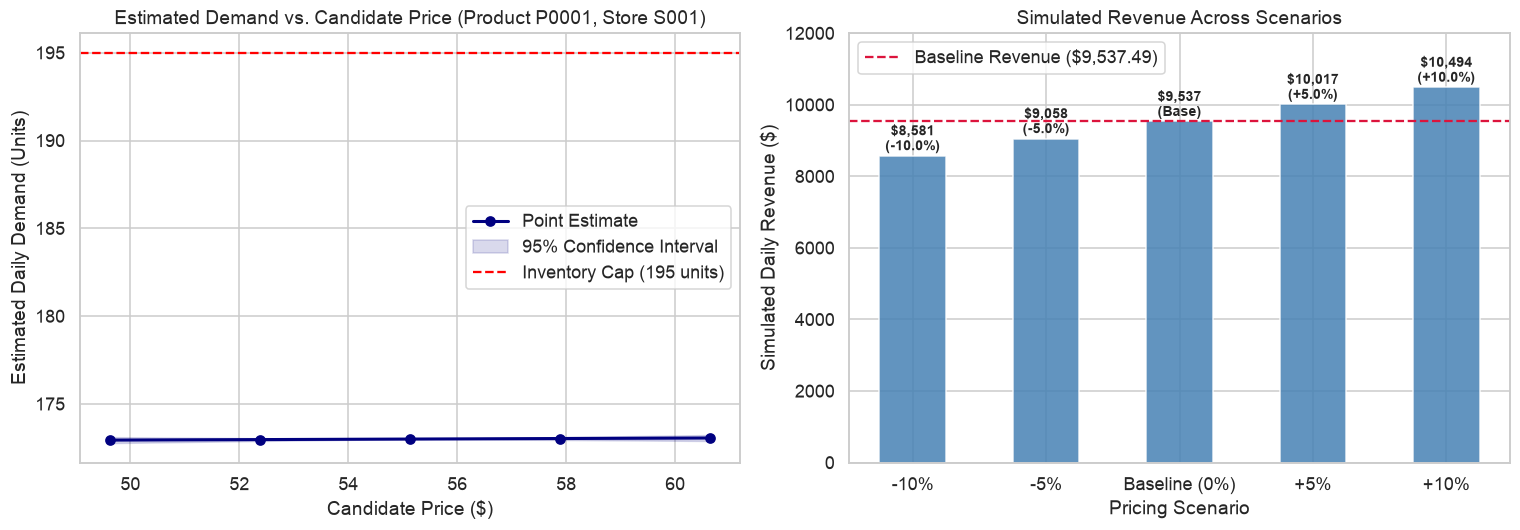

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Demand vs Price
axes[0].plot(benchmark_scens['candidate_price'], benchmark_scens['estimated_demand'], 'o-', color='navy', linewidth=2, label='Point Estimate')
axes[0].fill_between(benchmark_scens['candidate_price'], benchmark_scens['demand_ci_low'], benchmark_scens['demand_ci_high'], color='navy', alpha=0.15, label='95% Confidence Interval')
axes[0].axhline(195.0, color='red', linestyle='--', label='Inventory Cap (195 units)')
axes[0].set_title('Estimated Demand vs. Candidate Price (Product P0001, Store S001)')
axes[0].set_xlabel('Candidate Price ($)')
axes[0].set_ylabel('Estimated Daily Demand (Units)')
axes[0].legend()

# Plot 2: Revenue vs Scenario
axes[1].bar(benchmark_scens['scenario'], benchmark_scens['estimated_revenue'], color='steelblue', alpha=0.85, width=0.5)
axes[1].axhline(9537.49, color='crimson', linestyle='--', label='Baseline Revenue ($9,537.49)')
for i, r in benchmark_scens.reset_index().iterrows():
    diff_str = f"{r['revenue_diff_pct']:+.1f}%" if r['revenue_diff_pct'] != 0 else "Base"
    axes[1].text(i, r['estimated_revenue'] + 150, f"${r['estimated_revenue']:,.0f}\n({diff_str})", ha='center', fontsize=9, fontweight='bold')
axes[1].set_ylim(0, 12000)
axes[1].set_title('Simulated Daily Revenue Across Scenarios')
axes[1].set_xlabel('Pricing Scenario')
axes[1].set_ylabel('Simulated Daily Revenue ($)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 3 · The Revenue vs. Profit Gap & The Missing Cost Accounting Problem

A fundamental flaw in naive dynamic pricing algorithms is confusing **revenue maximization** with **profit maximization**.

### Mathematical Derivation of Operating Profit:
$$\Pi(P) = (P - c) \cdot \text{Sales}(P) - F$$
where:
- $c$ is the marginal wholesale procurement cost (Cost of Goods Sold / COGS).
- $F$ is fixed store operating overhead.
- $(P - c)$ is the unit gross contribution margin.

Differentiating with respect to price $P$:
$$\frac{d\Pi}{dP} = \text{Sales}(P) + (P - c) \frac{d\text{Sales}}{dP} = \frac{d\text{Revenue}}{dP} - c \frac{d\text{Sales}}{dP}$$

Because marginal cost $c > 0$, whenever demand responds negatively to price ($\frac{d\text{Sales}}{dP} < 0$), $-c \frac{d\text{Sales}}{dP} > 0$. Thus:
$$\frac{d\Pi}{dP} > \frac{d\text{Revenue}}{dP}$$

This proves that **the profit-maximizing price is strictly higher and volume is strictly lower than the revenue-maximizing price**.


In [5]:
# Inspect available dataset columns
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'retail_inventory_cleaned.csv'
df_raw = pd.read_csv(DATA_PATH)
available_cols = df_raw.columns.tolist()

cost_keywords = ['cost', 'cogs', 'wholesale', 'procurement', 'margin', 'purchase_price']
matching_cost_cols = [c for c in available_cols if any(k in c.lower() for k in cost_keywords)]

print("DATASET COST AUDIT:")
print(f"  Total columns in dataset : {len(available_cols)}")
print(f"  Columns list             : {available_cols}")
print(f"  Matching cost columns    : {matching_cost_cols}")
print(f"  Unit cost available?     : {len(matching_cost_cols) > 0}")

if len(matching_cost_cols) == 0:
    print("\n[CRITICAL BUSINESS LIMITATION CONFIRMED]")
    print("Unit cost information is unavailable in the retail dataset.")
    print("Formal profit optimization cannot yet be performed without product cost accounting data.")


DATASET COST AUDIT:
  Total columns in dataset : 14
  Columns list             : ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']
  Matching cost columns    : []
  Unit cost available?     : False

[CRITICAL BUSINESS LIMITATION CONFIRMED]
Unit cost information is unavailable in the retail dataset.
Formal profit optimization cannot yet be performed without product cost accounting data.


## 4 · Category-Specific Portfolio Evaluations

To ensure robustness across product lines, we evaluate representative products across all 5 retail categories using category-specific DML estimates established during Day 15 robustness testing.


In [6]:
cat_scens = scen_df[scen_df['case_type'] == 'Category Specific'].copy()
cat_summary = cat_scens.groupby('category').agg(
    Base_Price=('baseline_price', 'first'),
    Base_Units=('baseline_units', 'first'),
    Base_Revenue=('estimated_revenue', lambda s: s.iloc[2]), # 0% scenario
    DML_Theta=('dml_theta_used', 'first'),
    Plus10_Rev_Pct=('revenue_diff_pct', lambda s: s.iloc[4]), # +10% scenario
    Minus10_Rev_Pct=('revenue_diff_pct', lambda s: s.iloc[0]) # -10% scenario
).reset_index()

display(cat_summary.round(3))


category,Base_Price,Base_Units,Base_Revenue,DML_Theta,Plus10_Rev_Pct,Minus10_Rev_Pct
Clothing,55.13,137.13,7559.98,-0.022,9.90,-9.91
Electronics,53.89,133.13,7174.38,-0.001,10.00,-10.00
Furniture,54.70,137.82,7538.75,-0.016,9.93,-9.94
Groceries,55.06,137.31,7560.29,0.043,10.20,-10.16
Toys,55.45,131.04,7266.17,0.002,10.02,-10.02


## 5 · Strategic Pricing Recommendations & Governance Matrix

Based on econometric findings, the Decision Engine establishes the following operational governance rules:

1. **Reject All Broad Price Cuts ($-5\%$, $-10\%$):**
   - Because demand elasticity is near zero, lowering prices reduces revenue by approximately $-5.02\%$ to $-10.03\%$ with zero compensatory volume expansion. Discounting is purely value-destructive in this empirical regime.
2. **Treat $+10\%$ Revenue Gains as an Upper-Bound Simulation:**
   - Simulated revenue expansion of $+10.03\%$ assumes that consumers are completely indifferent to price hikes. Because $\theta$ is not statistically significant ($p = 0.49$) and parameter confidence intervals span negative values ($\theta_{\text{low}} = -0.0197$), uncritical price hikes across the catalog risk unobserved customer churn.
3. **Execute Controlled Micro-Pilots Prior to Catalog Rollout:**
   - Implement localized $\pm 2\%$ price testing on selected store-product pairs before adjusting catalog pricing.


In [7]:
SCENARIO_EXPORT_PATH = REPORTS_DIR / 'day17_pricing_scenarios.csv'
scen_df.to_csv(SCENARIO_EXPORT_PATH, index=False)

print(f"Successfully generated {len(scen_df)} scenarios.")
print(f"Exported to: {SCENARIO_EXPORT_PATH}")


Successfully generated 30 scenarios.
Exported to: /Users/hasikaippili/Documents/EconoCausal/reports/day17_pricing_scenarios.csv
